### Deep Agents overview



Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.


### When to use deep agents
Use deep agents when you need agents that can:

- Handle complex, multi-step tasks that require planning and decomposition
- Manage large amounts of context through file system tools
- Delegate work to specialized subagents for context isolation
- Persist memory across conversations and threads

In [2]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

#os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [3]:
from typing import Literal

In [4]:
### Tools- Internet search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)



In [5]:
from langchain.chat_models import init_chat_model

model=init_chat_model("groq:qwen/qwen3.8-27b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, client=<groq.resources.chat.completions.Completions object at 0x113a66390>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x113d139e0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

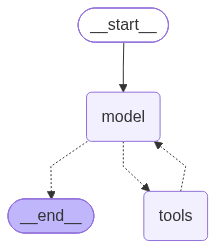

In [6]:
## Basic Agent
from langchain.agents import create_agent


simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

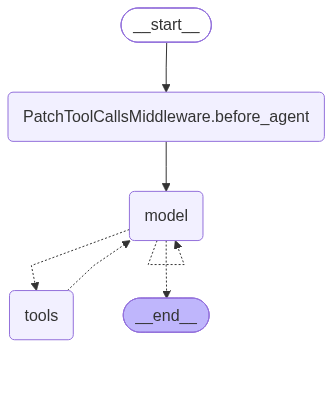

In [11]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [12]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='9871dbea-0882-4408-bf0a-d7ee53df899c'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'a717m3nhh', 'function': {'arguments': '{"query":"deepagent what is it"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 30, 'prompt_tokens': 2850, 'total_tokens': 2880, 'completion_time': 0.086379514, 'completion_tokens_details': None, 'prompt_time': 0.208904012, 'prompt_tokens_details': None, 'queue_time': 0.059772473, 'total_time': 0.295283526}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12f94-6357-7ba2-9681-1b3fd935af67-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'deepagent what is it'}, 'id': 'a717m3nhh', 'type': 'tool_call'}], invalid_tool_calls=[], usage_met

In [13]:
result["messages"][-1].content

'# Deep Agents\n\n**"Deep agents"** are AI agents designed to handle **complex, open-ended, long-running tasks** — as opposed to "shallow" agents that handle narrow, clearly defined jobs like single-shot report generation or basic RAG. The term was popularized by **LangChain**, which also shipped a concrete library by that name.\n\n## Key Characteristics\n\nA deep agent is defined by **structure**, not just autonomy:\n\n- **Explicit planning** — it reasons about goals and breaks them into subtasks before acting\n- **Persistent memory** — it tracks state and progress across many steps\n- **Tool execution** — it uses tools (filesystem, shell, search, code execution, etc.)\n- **Subagent delegation** — specialized, isolated worker agents handle delegated subtasks in their own context, then results are combined by the orchestrator\n- **Reusable skills** and adaptive plans that update as new information arrives\n\n## The LangChain `deepagents` Library\n\nThis is the most concrete, well-known

In [14]:
result['files']

{}

### What happened?

Your deep agent automatically:
- Planned its approach: Used the built-in write_todos tool to break down the research task
- Conducted research: Called the internet_search tool to gather information
- Managed context: Used file system tools (write_file, read_file) to offload large search results
- Spawned subagents (if needed): Delegated complex subtasks to specialized subagents
- Synthesized a report: Compiled findings into a coherent response

### Customizing Deep Agents

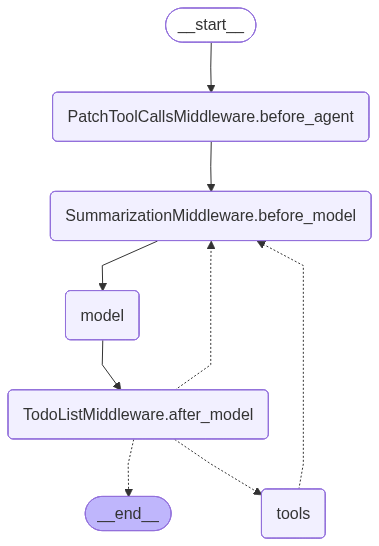

In [10]:
## #Model
from langchain.chat_models import init_chat_model
from deepagents import create_deep_agent

model = init_chat_model(model="gpt-5")
agent = create_deep_agent(model=model)
agent

In [11]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='4958884a-de7d-4cd8-814c-b6e97386faa1'),
  AIMessage(content='Do you mean “deep agent” in general, or something specifically named “DeepAgent”? A few possibilities:\n\n- Generic concept: a deep agent is an autonomous AI agent that uses deep learning (often LLMs plus tools, memory, and planners) to perceive, reason, and act.\n- RL libraries: several open‑source projects named “DeepAgent” provide frameworks for deep reinforcement learning experiments in Python.\n- Security products: some vendors use “DeepAgent” to refer to an endpoint protection/EDR agent powered by deep learning.\n- Customer support/ops: a few companies brand their GenAI contact-center agents as “DeepAgent.”\n\nIf you can share a link or the context (library, product, or paper), I can give a precise explanation.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 803, 'prompt

### System Prompt
Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents.
Each deep agent tailored to a use case should include a custom system prompt specific to that use case.

In [17]:
from deepagents import create_deep_agent

research_instructions = """\
You are an expert researcher. Your job is to conduct \
thorough research, and then write a polished report. \
"""

agent = create_deep_agent(
    model=model,
    system_prompt=research_instructions,
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='472a54aa-f8df-4740-a7c1-6e6a8f9c33ae'),
  AIMessage(content='Could you share a bit more context? “DeepAgent” refers to several different things, including:\n- An open-source Python library/framework for deep reinforcement learning (often styled deepagent/DeepAgent on GitHub/PyPI)\n- A few commercial “AI agent”/automation products branded DeepAgent\n- Research projects/papers that use “DeepAgent” as a model or system name\n\nIf you can point me to a link, the domain (RL library vs. commercial product vs. research), or where you heard it, I can give a precise explanation and a concise comparison to related tools.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 834, 'prompt_tokens': 4475, 'total_tokens': 5309, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 704, 'rejected_prediction_tok

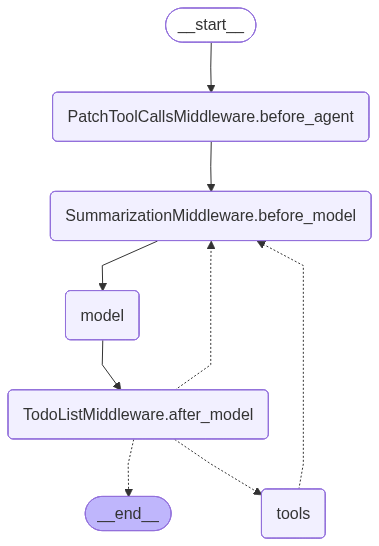

In [18]:
agent

In [20]:
### Tools
import os
from typing import Literal
from tavily import TavilyClient
from deepagents import create_deep_agent

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

agent = create_deep_agent(
    model=model,
    tools=[internet_search]
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent in Agentic AI?"}]})
result

{'messages': [HumanMessage(content='What is deepagent in Agentic AI?', additional_kwargs={}, response_metadata={}, id='69e9c583-1d34-434c-8e41-c738f304dd3f'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 179, 'prompt_tokens': 4518, 'total_tokens': 4697, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 4480}}, 'model_provider': 'openai', 'model_name': 'gpt-5-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Cw0gZziJDWPV92ctxVNPRkpCzTPZI', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019ba189-648b-7ad2-b64f-308d8b3b40e4-0', tool_calls=[{'name': 'internet_search', 'args': {'query': 'deepagent Agentic AI what is Deepagent', 'max_results': 5, 'topic': 'general', 'include_raw_content': False}, 'id': 'call_zeMOL3WtSWtgfh